# Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp

# Global parameters
sigma, b = 10.0, 8.0 / 3.0
r_kaos = 28.0
r_list = [15.0, 22.0, 28.0]
y0 = [1.0, 1.0, 1.0]
d0 = 1e-8
t_end = 40.0

rtol, atol = 1e-11, 1e-13

# Funkcije

In [2]:
# Simbolno: Lorenzov sistem, ravnotezja, divergenca, Jacobijeva matrika
x, y, z = sp.symbols("x y z", real=True)
s_s, r_s, b_s = sp.symbols("sigma r b", positive=True)
f_sym = sp.Matrix([s_s * (y - x), r_s * x - y - x * z, x * y - b_s * z])
J_sym = f_sym.jacobian([x, y, z])
div_sym = J_sym.trace()
ravnotezja = sp.solve(list(f_sym), [x, y, z], dict=True)

In [3]:
def lorenz(t, u, r):
    x, y, z = u
    return [sigma * (y - x), r * x - y - x * z, x * y - b * z]

def simuliraj(u0, r, t_end, n=20000):
    t = np.linspace(0, t_end, n + 1)
    return solve_ivp(lorenz, (0, t_end), u0, args=(r,), t_eval=t, method="RK45", rtol=rtol, atol=atol)

def lorenz_var(t, u, r):
    # Lorenz + variacijske enacbe M' = J M (za krcenje volumna in raztezanje)
    X, M = u[:3], u[3:].reshape(3, 3)
    x, y, z = X
    J = np.array([[-sigma, sigma, 0], [r - z, -1, -x], [y, x, -b]])
    return np.concatenate([lorenz(t, X, r), (J @ M).ravel()])

# Testno območje

In [4]:
# Pripravljalna naloga
par = {s_s: sigma, r_s: r_kaos, b_s: sp.Rational(8, 3)}
for rv in ravnotezja:
    display(sp.Matrix([rv[x], rv[y], rv[z]]).T)
display(sp.Eq(sp.Symbol(r"\mathrm{div}\,f"), div_sym))
print(f"div f (sigma = 10, b = 8/3) = {float(div_sym.subs(par)):.4f}")

for rv in ravnotezja:
    tocka = {k: v.subs(par) for k, v in rv.items()}
    lam = np.linalg.eigvals(np.array(J_sym.subs(par).subs(tocka), dtype=float))
    print(f"r = 28, tocka ({float(tocka[x]):+.3f}, {float(tocka[y]):+.3f}, {float(tocka[z]):.0f}):  lambda = {np.round(lam, 3)}")

r_H = sigma * (sigma + b + 3) / (sigma - b - 1)
print(f"Hopfova bifurkacija C1,2 pri r_H = {r_H:.2f}")

Matrix([[0, 0, 0]])

Matrix([[-sqrt(b)*sqrt(r - 1), -sqrt(b)*sqrt(r - 1), r - 1]])

Matrix([[sqrt(b)*sqrt(r - 1), sqrt(b)*sqrt(r - 1), r - 1]])

Eq(\mathrm{div}\,f, -b - sigma - 1)

div f (sigma = 10, b = 8/3) = -13.6667
r = 28, tocka (+0.000, +0.000, 0):  lambda = [-22.828+0.j  11.828+0.j  -2.667+0.j]
r = 28, tocka (-8.485, -8.485, 27):  lambda = [-13.855 +0.j      0.094+10.195j   0.094-10.195j]
r = 28, tocka (+8.485, +8.485, 27):  lambda = [-13.855 +0.j      0.094+10.195j   0.094-10.195j]
Hopfova bifurkacija C1,2 pri r_H = 24.74


# Naloga 1

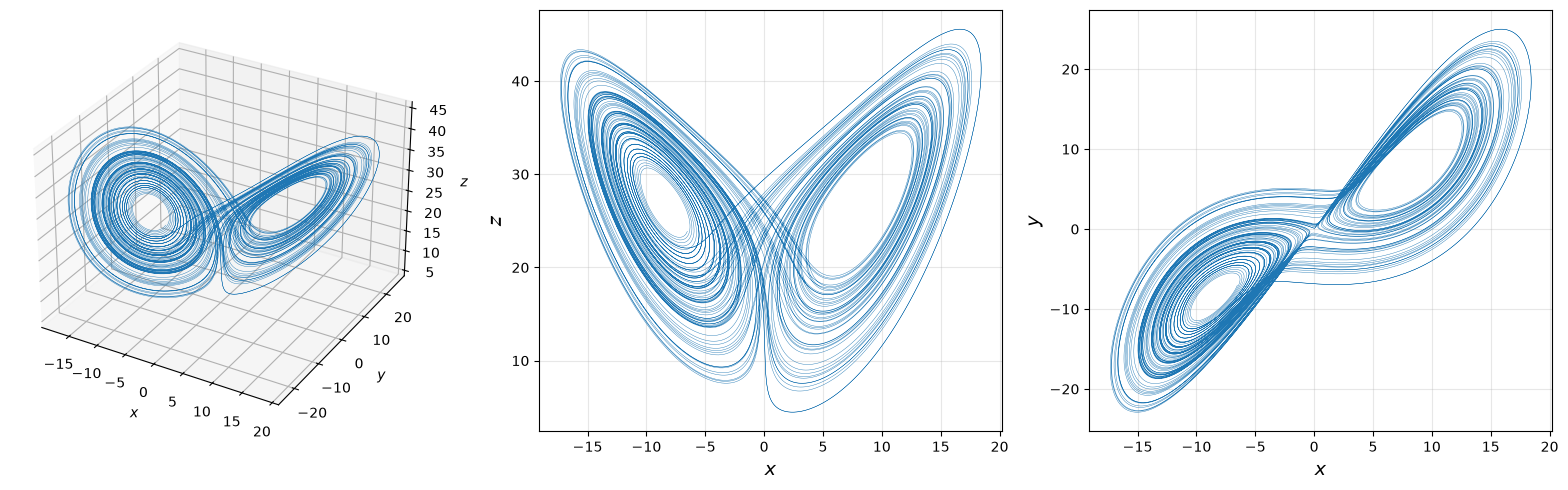

In [5]:
sol = simuliraj(y0, r_kaos, 100.0, n=40000)
m_ = sol.t > 5    # izpustimo prehodni del

fig = plt.figure(figsize=(16, 5))
ax = fig.add_subplot(131, projection="3d")
ax.plot(*sol.y[:, m_], linewidth=0.3)
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_zlabel("$z$")

for i, (a, b_, oz) in enumerate([(0, 2, ("$x$", "$z$")), (0, 1, ("$x$", "$y$"))]):
    ax = fig.add_subplot(1, 3, i + 2)
    ax.plot(sol.y[a, m_], sol.y[b_, m_], linewidth=0.3)
    ax.set_xlabel(oz[0], fontsize=14)
    ax.set_ylabel(oz[1], fontsize=14)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

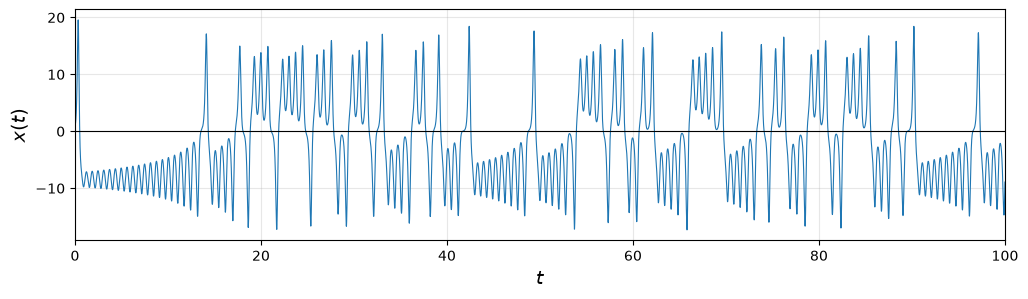

stevilo preklopov med kriloma v t = [5, 100]: 44


In [6]:
# Preklapljanje med kriloma: predznak x(t)
fig = plt.figure(figsize=(12, 3))
ax = fig.add_subplot(111)
ax.plot(sol.t, sol.y[0], linewidth=0.8)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("$t$", fontsize=14)
ax.set_ylabel("$x(t)$", fontsize=14)
ax.set_xlim(0, 100)
ax.grid(alpha=0.3)
plt.show()
n_prekl = np.sum(np.diff(np.sign(sol.y[0][m_])) != 0)
print(f"stevilo preklopov med kriloma v t = [5, 100]: {n_prekl}")

# Naloga 2

t_pred (|x1 - x2| > 1): 31.42


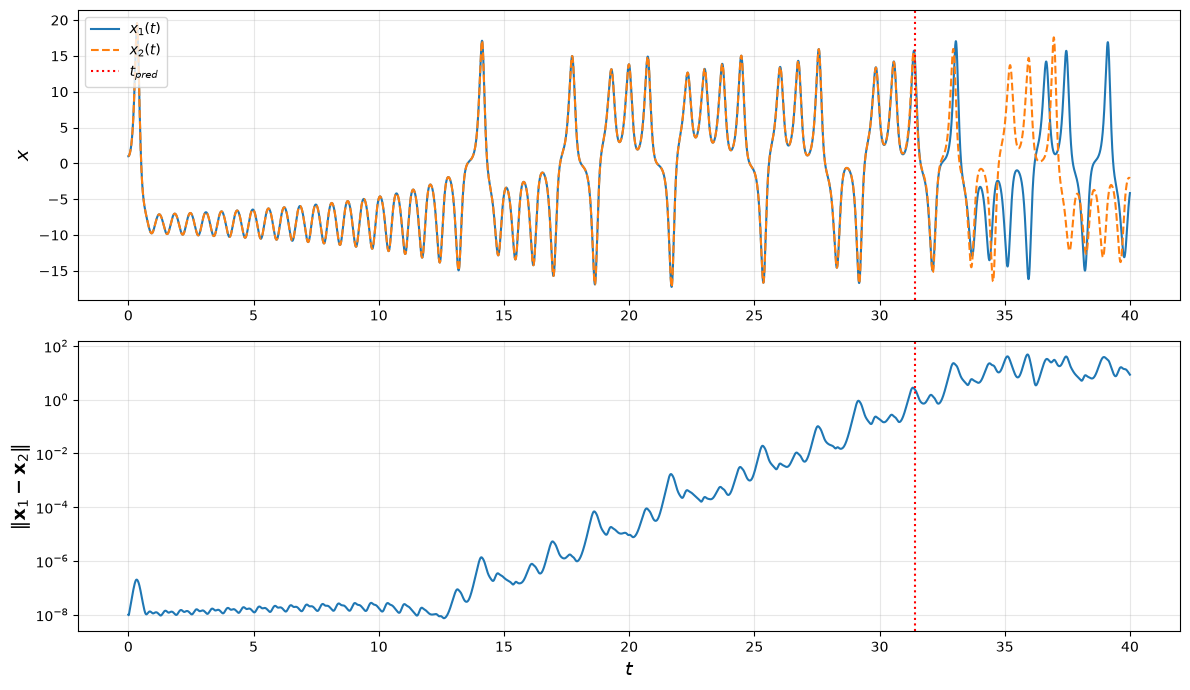

In [7]:
s1 = simuliraj(y0, r_kaos, t_end)
s2 = simuliraj([y0[0] + d0, y0[1], y0[2]], r_kaos, t_end)
razlika = np.linalg.norm(s1.y - s2.y, axis=0)
t_pred = s1.t[np.argmax(np.abs(s1.y[0] - s2.y[0]) > 1.0)]
print(f"t_pred (|x1 - x2| > 1): {t_pred:.2f}")

fig = plt.figure(figsize=(12, 7))
ax = fig.add_subplot(211)
ax.plot(s1.t, s1.y[0], label=r"$x_1(t)$")
ax.plot(s2.t, s2.y[0], "--", label=r"$x_2(t)$")
ax.axvline(t_pred, color="red", linestyle=":", label=r"$t_{pred}$")
ax.set_ylabel("$x$", fontsize=14)
ax.legend(loc="upper left")
ax.grid(alpha=0.3)

ax = fig.add_subplot(212)
ax.semilogy(s1.t, razlika)
ax.axvline(t_pred, color="red", linestyle=":")
ax.set_xlabel("$t$", fontsize=14)
ax.set_ylabel(r"$\|\mathbf{x}_1 - \mathbf{x}_2\|$", fontsize=14)
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

# Naloga 3

r = 15: koncno stanje (-6.110, -6.110, 14.000),  C = (+-6.110, +-6.110, 14)
r = 22: koncno stanje (-7.484, -7.484, 20.999),  C = (+-7.483, +-7.483, 21)
r = 28: koncno stanje (-8.917, -1.116, 35.241),  C = (+-8.485, +-8.485, 27)


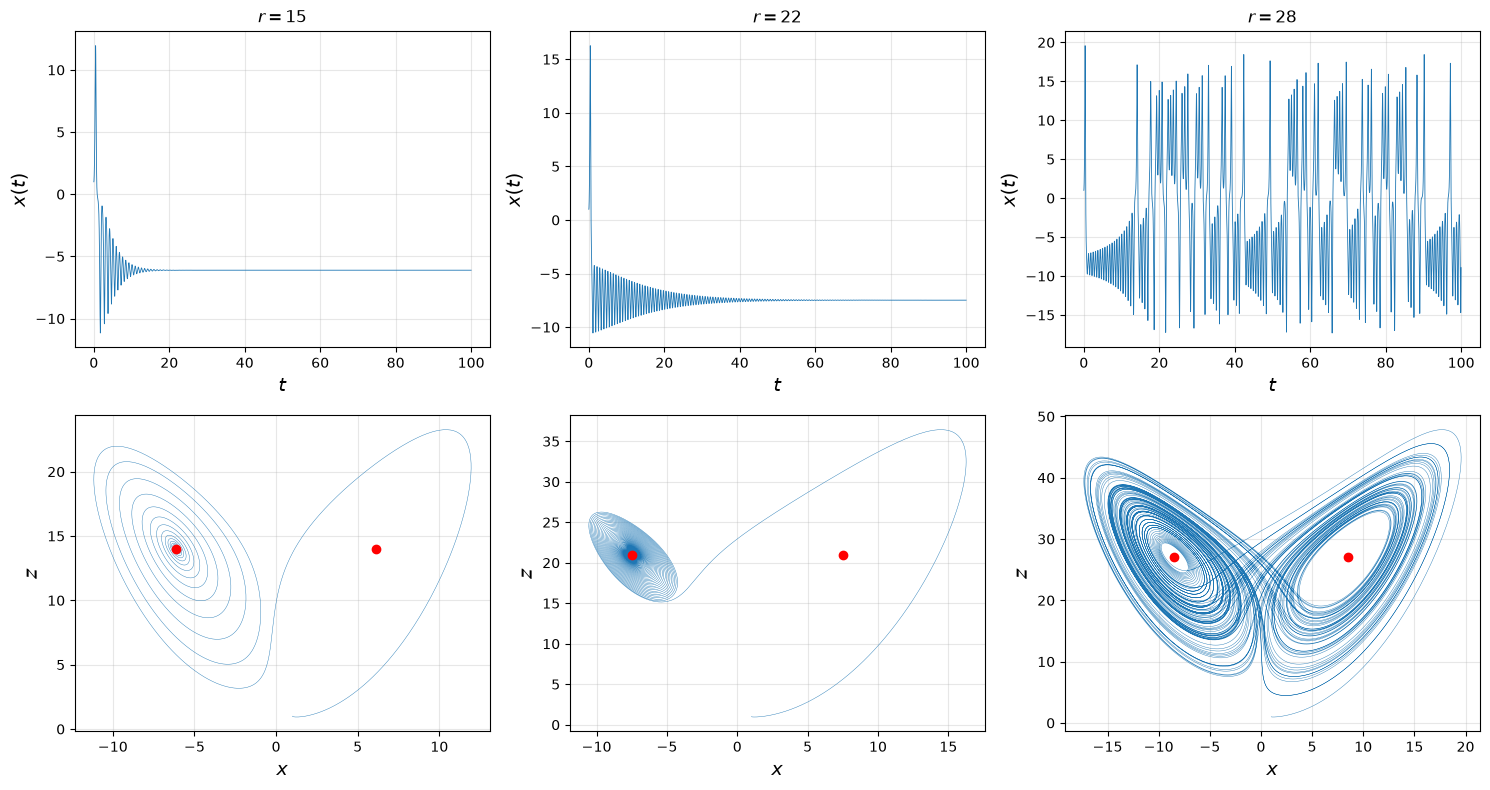

In [8]:
fig = plt.figure(figsize=(15, 8))
for i, r in enumerate(r_list):
    s = simuliraj(y0, r, 100.0, n=40000)
    ax = fig.add_subplot(2, 3, i + 1)
    ax.plot(s.t, s.y[0], linewidth=0.6)
    ax.set_title(f"$r = {r:.0f}$")
    ax.set_xlabel("$t$", fontsize=14)
    ax.set_ylabel("$x(t)$", fontsize=14)
    ax.grid(alpha=0.3)
    ax = fig.add_subplot(2, 3, i + 4)
    ax.plot(s.y[0], s.y[2], linewidth=0.3)
    C = np.sqrt(b * (r - 1))
    ax.plot([C, -C], [r - 1, r - 1], "o", color="red")
    ax.set_xlabel("$x$", fontsize=14)
    ax.set_ylabel("$z$", fontsize=14)
    ax.grid(alpha=0.3)
    print(f"r = {r:.0f}: koncno stanje ({s.y[0, -1]:+.3f}, {s.y[1, -1]:+.3f}, {s.y[2, -1]:.3f}),  C = (+-{C:.3f}, +-{C:.3f}, {r - 1:.0f})")
plt.tight_layout()
plt.show()

# Razmislek 1

In [9]:
# Fundamentalna matrika M(t): det M = V(t)/V(0) (krcenje), singularne vrednosti = raztezanje / stiskanje
u0 = np.concatenate([s1.y[:, -1], np.eye(3).ravel()])   # zacnemo na atraktorju
t_v = np.linspace(0, 2.0, 21)
sv = solve_ivp(lorenz_var, (0, 2.0), u0, args=(r_kaos,), t_eval=t_v, rtol=rtol, atol=atol)

print(f"{'t':>4} {'det M':>11} {'exp(-(s+1+b)t)':>15} {'sigma_max':>10} {'sigma_min':>10}")
for k in range(0, len(t_v), 4):
    M = sv.y[3:, k].reshape(3, 3)
    sing = np.linalg.svd(M, compute_uv=False)
    print(f"{t_v[k]:4.1f} {np.linalg.det(M):11.3e} {np.exp(-(sigma + 1 + b) * t_v[k]):15.3e} {sing[0]:10.3e} {sing[-1]:10.3e}")

   t       det M  exp(-(s+1+b)t)  sigma_max  sigma_min
 0.0   1.000e+00       1.000e+00  1.000e+00  1.000e+00
 0.4   4.225e-03       4.225e-03  5.538e+00  1.370e-03
 0.8   1.785e-05       1.785e-05  2.625e+00  1.092e-05
 1.2   7.543e-08       7.543e-08  1.968e+01  9.749e-09
 1.6   3.187e-10       3.187e-10  6.771e+00  9.105e-11
 2.0   1.140e-12       1.347e-12  1.505e+02  2.991e-14
